# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Вариант CV. Я использовал YOLO26n (`ultralytics==8.4.0`) и датасет BCCD под лицензией MIT. Финальный прогон сделал в Google Colab на Tesla T4 с `FAST_MODE=False`. Выполнил все обязательные пункты и выбрал бонус 6.3.

Использовал исходный шаблон ДЗ, документацию и код Ultralytics. [BCCD](https://github.com/Shenggan/BCCD_Dataset/tree/d272fb14cdff6e473fafeeeba32aba5f560e9e43) · [YOLO26](https://docs.ultralytics.com/models/yolo26/) · [Ultralytics v8.4.0](https://github.com/ultralytics/ultralytics/tree/v8.4.0)


In [ ]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
# ваш код
from importlib.metadata import version, PackageNotFoundError
try:
    installed = version('ultralytics')
except PackageNotFoundError:
    installed = None
if installed != '8.4.0':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.0'], check=True)

import csv
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')
from IPython.display import display, Markdown
import pandas as pd
import urllib.request, zipfile


assert ultralytics.__version__ == "8.4.0", "После смены версии перезапустите среду."


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.4.0, torch 2.14.1+cu130, device: Tesla T4


In [ ]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64   # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
# ваш код
RUNS = Path("runs_hw2_fast" if FAST_MODE else "runs_hw2_final")

base_dir=Path('/content') if Path('/content').exists() else Path.cwd()
SESSION_ROOT=base_dir/f"hw2_cv_{'fast' if FAST_MODE else 'final'}_{time.time_ns()}"
SESSION_ROOT.mkdir(parents=True,exist_ok=False)
os.chdir(SESSION_ROOT)
print('Isolated run directory:', SESSION_ROOT)


Isolated run directory: /content/hw2_cv_final_1795111045473326427


Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [ ]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [ ]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
# ваш код
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
    size_mb=weights_path.stat().st_size / 1024**2,
    params=sum(p.numel() for p in model_coco.model.parameters()),
    n_classes_coco=len(model_coco.names))
def sync_device():
    if torch.cuda.is_available(): torch.cuda.synchronize()
    elif DEVICE == 'mps': torch.mps.synchronize()
dummy = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
for _ in range(5): model_coco.predict(dummy, imgsz=IMGSZ, device=DEVICE, verbose=False)
timings=[]
for _ in range(20):
    sync_device(); start=time.perf_counter()
    model_coco.predict(dummy, imgsz=IMGSZ, device=DEVICE, verbose=False)
    sync_device(); timings.append((time.perf_counter()-start)*1000)
MODEL_INFO.update(latency_ms=float(np.mean(timings)), latency_std_ms=float(np.std(timings)),
                  latency_protocol='batch=1, numpy RGB input, preprocess+forward+postprocess, 5 warmups + 20 repeats')
print(json.dumps(MODEL_INFO,indent=2))


{
  "ultralytics": "8.4.0",
  "weights": "yolo26n.pt",
  "size_mb": 5.287602424621582,
  "params": 2572280,
  "n_classes_coco": 80,
  "latency_ms": 11.993146650002018,
  "latency_std_ms": 1.9243971830445048,
  "latency_protocol": "batch=1, numpy RGB input, preprocess+forward+postprocess, 5 warmups + 20 repeats"
}


In [ ]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.0',
 'weights': 'yolo26n.pt',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 11.993146650002018,
 'latency_std_ms': 1.9243971830445048,
 'latency_protocol': 'batch=1, numpy RGB input, preprocess+forward+postprocess, 5 warmups + 20 repeats'}

**Ответ:** Я выбрал YOLO26n, потому что у меня 364 снимка и на T4 нужно успеть провести два обучения. В таблице Ultralytics у n и s соответственно 2,4 и 9,5 млн параметров, mAP50–95 на COCO — 40,9% и 48,6% (в режиме end-to-end — 40,1% и 47,8%), время на T4 с TensorRT — 1,7 и 2,5 мс. У полного checkpoint до слияния слоёв я насчитал 2 572 280 параметров. В сохранённом замере на T4 вызов `predict` для кадра 640×640 занимал в среднем 11,99 мс с учётом подготовки изображения и обработки результата.


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [ ]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model   # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])   # первые n_backbone слоев - backbone, последний - Detect
    # ваш код
    count=lambda modules: sum(p.numel() for m in modules for p in m.parameters())
    return dict(backbone=count(layers[:n_backbone]), neck=count(layers[n_backbone:-1]), head=count(layers[-1:]))

def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    # ваш код
    observed=[]
    def pre_hook(module, args):
        observed.extend(tuple(t.shape) for t in args[0])
    handle=det_model.model[-1].register_forward_pre_hook(pre_hook)
    states={m:m.training for m in det_model.modules()}
    p=next(det_model.parameters())
    try:
        det_model.eval()
        with torch.inference_mode():
            out=det_model(torch.zeros(1,3,imgsz,imgsz,device=p.device,dtype=p.dtype))
    finally:
        handle.remove()
        for m,state in states.items(): m.training=state
    return observed,out

def shapes(obj):
    if isinstance(obj, torch.Tensor): return tuple(obj.shape)
    if isinstance(obj, (list, tuple)): return [shapes(o) for o in obj]
    if isinstance(obj, dict): return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__


In [ ]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [ ]:
# ваш код
print('Выход:', shapes(out))
print('Слои:', [(i,type(m).__name__) for i,m in enumerate(arch.model)])


Выход: [(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]
Слои: [(0, 'Conv'), (1, 'Conv'), (2, 'C3k2'), (3, 'Conv'), (4, 'C3k2'), (5, 'Conv'), (6, 'C3k2'), (7, 'Conv'), (8, 'C3k2'), (9, 'SPPF'), (10, 'C2PSA'), (11, 'Upsample'), (12, 'Concat'), (13, 'C3k2'), (14, 'Upsample'), (15, 'Concat'), (16, 'C3k2'), (17, 'Conv'), (18, 'Concat'), (19, 'C3k2'), (20, 'Conv'), (21, 'Concat'), (22, 'C3k2'), (23, 'Detect')]


**Ответ:** Backbone выделяет признаки из изображения. Neck соединяет признаки трёх масштабов, чтобы у головы были и мелкие детали, и контекст. На входе 640×640 карты имеют размер 80×80, 40×40 и 20×20. Всего получается 80² + 40² + 20² = 8400 позиций. Голова предсказывает четыре числа для бокса и оценки классов в каждой позиции. Anchor-free означает, что модель опирается на точки этих карт без заранее заданных прямоугольников.

При обучении `one2many` связывает один объект с несколькими позициями. Ветка `one2one` учится оставлять одно предсказание на объект. При инференсе она позволяет отбирать предсказания без отдельного NMS. Я насчитал 1 365 472 параметра в backbone (53,08%), 897 152 в neck (34,88%) и 309 656 в голове (12,04%).


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [ ]:
# ваш код
DATA_COMMIT='d272fb14cdff6e473fafeeeba32aba5f560e9e43'
DATA_URL=f'https://codeload.github.com/Shenggan/BCCD_Dataset/zip/{DATA_COMMIT}'
DATA_ROOT.mkdir(exist_ok=True)
archive=DATA_ROOT/'bccd.zip'
if not archive.exists(): urllib.request.urlretrieve(DATA_URL,archive)
source_root=DATA_ROOT/f'BCCD_Dataset-{DATA_COMMIT}'
if not source_root.exists():
    with zipfile.ZipFile(archive) as z: z.extractall(DATA_ROOT)
raw=source_root/'BCCD'
CLASSES=['RBC','WBC','Platelets']
DATASET_NAME=f'BCCD; https://github.com/Shenggan/BCCD_Dataset; MIT; commit={DATA_COMMIT}'
cleaning=Counter(); all_recs=[]
for xml in sorted((raw/'Annotations').glob('*.xml')):
    tree=ET.parse(xml).getroot()
    image=raw/'JPEGImages'/tree.findtext('filename')
    with Image.open(image) as im: width,height=im.size
    boxes=[]; labels=[]
    for obj in tree.findall('object'):
        name=obj.findtext('name'); b=obj.find('bndbox')
        original=np.array([float(b.findtext(k)) for k in ['xmin','ymin','xmax','ymax']],float)
        original[:2]-=1
        clipped=np.clip(original,[0,0,0,0],[width,height,width,height])
        cleaning['clipped']+=int(not np.array_equal(original,clipped))
        if not np.isfinite(clipped).all() or clipped[2]<=clipped[0] or clipped[3]<=clipped[1]:
            cleaning['removed_invalid']+=1; continue
        boxes.append(clipped); labels.append(CLASSES.index(name))
    all_recs.append(dict(image=image,width=width,height=height,
        boxes=np.asarray(boxes,np.float32).reshape(-1,4),labels=np.asarray(labels,np.int64)))
unique={}
for r in all_recs:
    with Image.open(r['image']) as im:
        pixels = (im.size, im.convert('RGB').tobytes())
    if pixels in unique:
        cleaning['duplicate_images']+=1
        old=unique[pixels]
        assert np.array_equal(old['labels'],r['labels']) and np.array_equal(old['boxes'],r['boxes']), 'Duplicate images with inconsistent labels'
    else:
        unique[pixels] = r
all_recs=list(unique.values())
del unique
order=np.random.default_rng(SEED).permutation(len(all_recs))
a,b=int(.70*len(order)),int(.85*len(order))
records={s:[all_recs[i] for i in ids] for s,ids in zip(['train','val','test'],[order[:a],order[a:b],order[b:]])}
assert len(all_recs)>=150
for recs in records.values():
    assert set(np.concatenate([r['labels'] for r in recs]))==set(range(len(CLASSES)))
print('Очистка:',dict(cleaning),'Сплиты:',{s:len(rs) for s,rs in records.items()})


Очистка: {'clipped': 0} Сплиты: {'train': 254, 'val': 55, 'test': 55}


In [ ]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 254, 'val': 55, 'test': 55}

,split,images,objects_per_image,RBC,WBC,Platelets
0,train,254,13.511811,2917,258,257
1,val,55,13.000000,604,57,54
2,test,55,13.472727,634,57,50


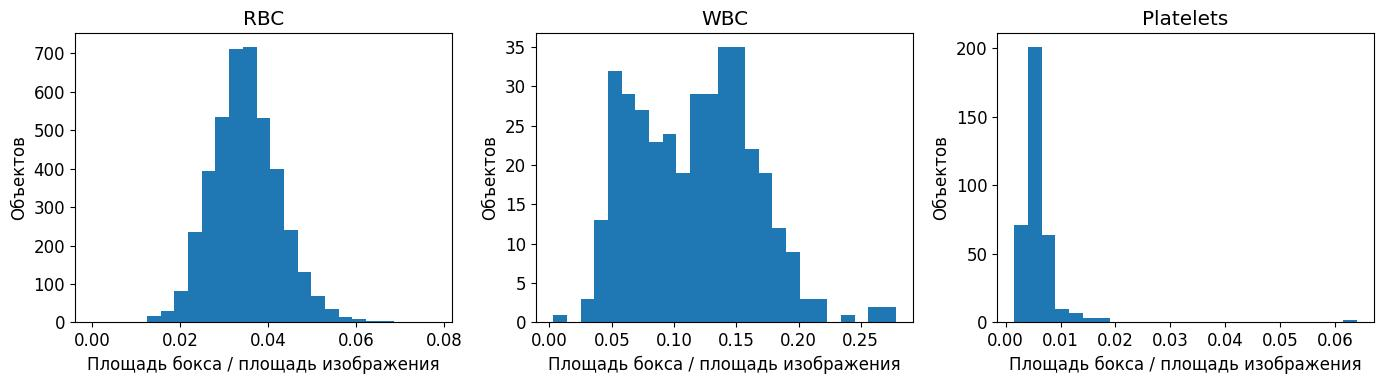

In [ ]:
# ваш код
stat_rows=[]; size_rows=[]
for split,recs in records.items():
    counts=np.bincount(np.concatenate([r['labels'] for r in recs]),minlength=len(CLASSES))
    stat_rows.append(dict(split=split,images=len(recs),objects_per_image=sum(counts)/len(recs),**dict(zip(CLASSES,counts))))
    for r in recs:
        wh=r['boxes'][:,2:]-r['boxes'][:,:2]
        for (w,h),c in zip(wh,r['labels']):
            size_rows.append(dict(split=split,cls=CLASSES[c],relative_area=w*h/(r['width']*r['height']),width=w,height=h))
stats=pd.DataFrame(stat_rows); sizes=pd.DataFrame(size_rows)
display(stats)
fig,axs=plt.subplots(1,3,figsize=(14,4))
for c,ax in zip(CLASSES,axs):
    ax.hist(sizes.loc[sizes.cls==c,'relative_area'],bins=25)
    ax.set(title=c,xlabel='Площадь бокса / площадь изображения',ylabel='Объектов')
plt.tight_layout(); plt.show()


**Ответ:** Я взял BCCD (MIT) с 364 микроскопическими снимками. Разделил их с seed 0 на 254 для обучения, 55 для валидации и 55 для теста. В датасете 4 155 эритроцитов (RBC), 372 лейкоцита (WBC) и 361 тромбоцит, то есть эритроцитов примерно в 11,5 раза больше, чем тромбоцитов. [BCCD](https://github.com/Shenggan/BCCD_Dataset)

В среднем на снимке 13,4 размеченного объекта. Медианный бокс тромбоцита — 40×40 пикселей, эритроцита — 106×102, лейкоцита — 202×182. Эритроциты часто перекрываются. На `BloodImage_00405.jpg` часть видимых по краям эритроцитов осталась без боксов. Нулевых боксов, выходов за границы и точных дубликатов изображений при проверке не встретилось.


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [ ]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    # ваш код
    if width<=0 or height<=0: raise ValueError('Image dimensions must be positive')
    boxes=np.asarray(boxes,dtype=float).reshape(-1,4); labels=np.asarray(labels).reshape(-1)
    if len(boxes)!=len(labels): raise ValueError('Mismatched boxes and labels')
    rows=[]
    for (x1,y1,x2,y2),label in zip(boxes,labels):
        if not np.isfinite([x1,y1,x2,y2]).all() or not (0<=x1<x2<=width and 0<=y1<y2<=height):
            raise ValueError('Expected finite, clipped, positive-area boxes')
        if label<0 or int(label)!=label: raise ValueError('Invalid class')
        rows.append(f'{int(label)} {(x1+x2)/(2*width):.6f} {(y1+y2)/(2*height):.6f} {(x2-x1)/width:.6f} {(y2-y1)/height:.6f}')
    return '\n'.join(rows)+('\n' if rows else '')

def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    # ваш код
    if width<=0 or height<=0: raise ValueError('Image dimensions must be positive')
    boxes=[]; labels=[]
    for line in text.splitlines():
        if not line.strip(): continue
        parts=line.split()
        if len(parts)!=5: raise ValueError('Expected class cx cy w h')
        c,cx,cy,w,h=map(float,parts)
        if not np.isfinite([c,cx,cy,w,h]).all() or c<0 or int(c)!=c: raise ValueError('Invalid values')
        if not (0<=cx<=1 and 0<=cy<=1 and 0<w<=1 and 0<h<=1): raise ValueError('Invalid normalized box')
        boxes.append([(cx-w/2)*width,(cy-h/2)*height,(cx+w/2)*width,(cy+h/2)*height]); labels.append(int(c))
    return np.asarray(boxes,np.float32).reshape(-1,4),np.asarray(labels,np.int64)


In [ ]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [ ]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    # ваш код
    image_dir=YOLO_ROOT/'images'/split; label_dir=YOLO_ROOT/'labels'/split
    image_dir.mkdir(parents=True,exist_ok=True); label_dir.mkdir(parents=True,exist_ok=True)
    stems=[Path(r['image']).stem for r in recs]
    assert len(stems)==len(set(stems)), 'Name collision'
    for r in recs:
        shutil.copy2(r['image'],image_dir/Path(r['image']).name)
        (label_dir/(Path(r['image']).stem+'.txt')).write_text(to_yolo(r['boxes'],r['labels'],r['width'],r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())


path: /content/hw2_cv_final_1795111045473326427/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



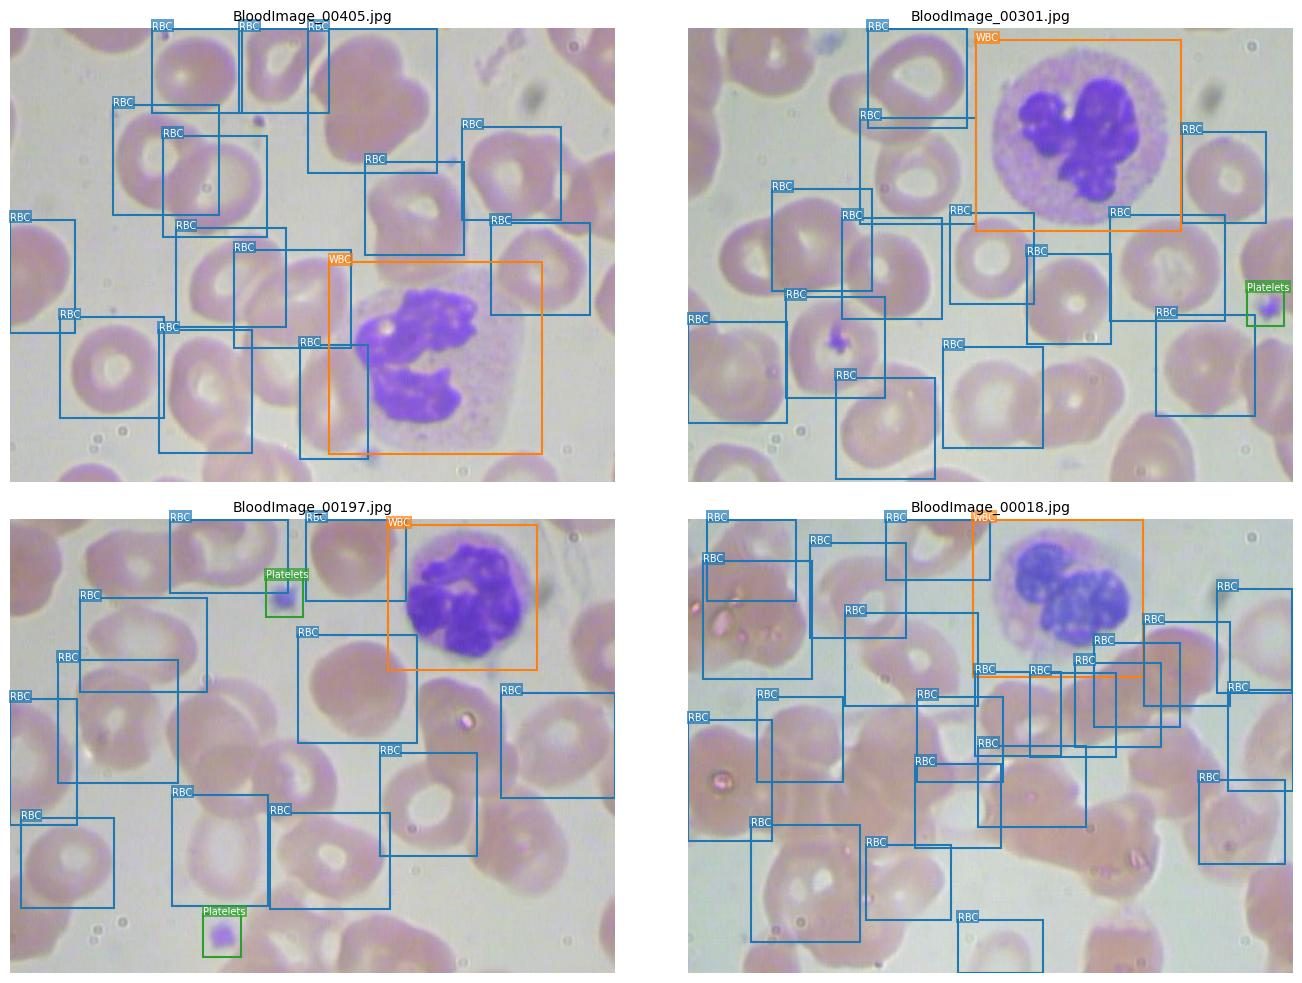

In [ ]:
# ваш код
roundtrip_error=0.
for split,recs in splits.items():
    for r in recs:
        txt=(YOLO_ROOT/'labels'/split/(Path(r['image']).stem+'.txt')).read_text()
        bb,ll=from_yolo(txt,r['width'],r['height'])
        assert np.array_equal(ll,r['labels'])
        assert np.allclose(bb,r['boxes'],atol=1e-5*max(r['width'],r['height'])+1e-3)
        if len(bb): roundtrip_error=max(roundtrip_error,float(np.max(abs(bb-r['boxes']))))
fig,axs=plt.subplots(2,2,figsize=(14,10))
for ax,r in zip(axs.flat,train_recs[:4]):
    bb,ll=from_yolo((YOLO_ROOT/'labels'/'train'/(Path(r['image']).stem+'.txt')).read_text(),r['width'],r['height'])
    draw_boxes(ax,Image.open(r['image']),bb,ll,CLASSES,title=Path(r['image']).name)
plt.tight_layout(); plt.show()


**Ответ:** Я записал боксы в YOLO-формат, прочитал обратно и сравнил координаты и классы с исходными. Проверка прошла на всех 364 изображениях. Если обе функции согласованно меняют местами оси, обратное преобразование может скрыть ошибку. На четырёх картинках я проверил, что рамки садятся на клетки. Так видно сдвиг бокса, перепутанные оси или бокс от соседнего изображения.


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

Классы COCO на тесте, conf>=0.05: Counter({'donut': 190, 'cake': 27, 'dining table': 21, 'apple': 19, 'bed': 19, 'person': 10, 'orange': 7, 'remote': 6, 'teddy bear': 4, 'keyboard': 2, 'tv': 1, 'dog': 1})


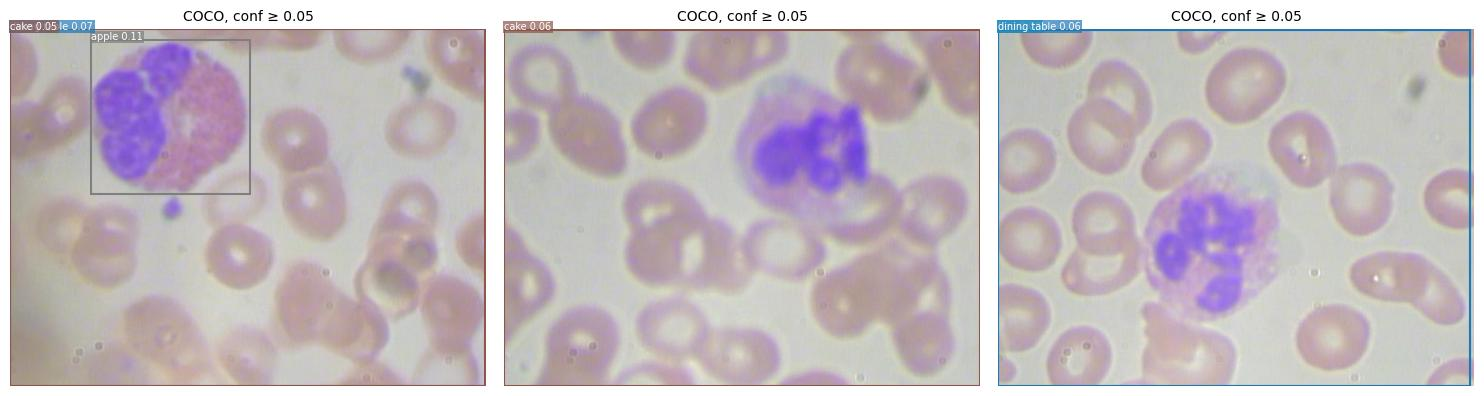

Совпадающие классы: {} mAP50: 0.0


In [ ]:
# ваш код
coco_raw=predict_records(model_coco,records[FINAL_SPLIT],conf=0.05)
coco_counts=Counter(model_coco.names[int(c)] for p in coco_raw for c in p['labels'])
print('Классы COCO на тесте, conf>=0.05:',coco_counts)
coco_mapping={i:CLASSES.index(name) for i,name in model_coco.names.items() if name in CLASSES}
coco_mapped=[]
for p in coco_raw:
    keep=np.array([int(c) in coco_mapping for c in p['labels']],bool)
    coco_mapped.append(dict(boxes=p['boxes'][keep],scores=p['scores'][keep],
        labels=np.array([coco_mapping[int(c)] for c in p['labels'][keep]],np.int64)))
coco_map50,coco_aps=evaluate_map50(coco_mapped,records[FINAL_SPLIT],len(CLASSES))
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,r,p in zip(axs,records[FINAL_SPLIT][:3],coco_raw[:3]):
    draw_boxes(ax,Image.open(r['image']),p['boxes'],p['labels'],model_coco.names,p['scores'],title='COCO, conf ≥ 0.05')
plt.tight_layout(); plt.show()
print('Совпадающие классы:',coco_mapping,'mAP50:',coco_map50)


In [ ]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    # ваш код
    with Image.open(image_path) as im: width,height=im.size
    boxes=[]; scores=[]; labels=[]
    for c,prior in HEURISTIC_PRIORS.items():
        n=prior['count']; gw=max(1,int(np.ceil(np.sqrt(n*width/height)))); gh=int(np.ceil(n/gw))
        bw,bh=prior['wh']*np.array([width,height])
        for k in range(n):
            cx=(k%gw+.5)*width/gw; cy=(k//gw+.5)*height/gh
            boxes.append([max(0,cx-bw/2),max(0,cy-bh/2),min(width,cx+bw/2),min(height,cy+bh/2)])
            scores.append(0.5); labels.append(c)
    return dict(boxes=np.asarray(boxes,np.float32).reshape(-1,4),scores=np.asarray(scores),labels=np.asarray(labels,np.int64))


In [ ]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)
HEURISTIC_PRIORS={}
for c in range(len(CLASSES)):
    wh=[]; counts=[]
    for r in train_recs:
        b=r['boxes'][r['labels']==c]; counts.append(len(b))
        wh.extend((b[:,2:]-b[:,:2])/[r['width'],r['height']])
    HEURISTIC_PRIORS[c]=dict(wh=np.median(wh,axis=0),count=max(1,int(round(np.mean(counts)))))
print({CLASSES[c]:{'wh':p['wh'].tolist(),'count':p['count']} for c,p in HEURISTIC_PRIORS.items()})


{'RBC': {'wh': [0.165625, 0.2125], 'count': 11}, 'WBC': {'wh': [0.3203125, 0.3802083333333333], 'count': 1}, 'Platelets': {'wh': [0.0625, 0.08125], 'count': 1}}


In [ ]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.004822769294294091,
 'heuristic_ap50_per_class': {'RBC': 0.014468307882882274,
  'WBC': 0.0,
  'Platelets': 0.0}}

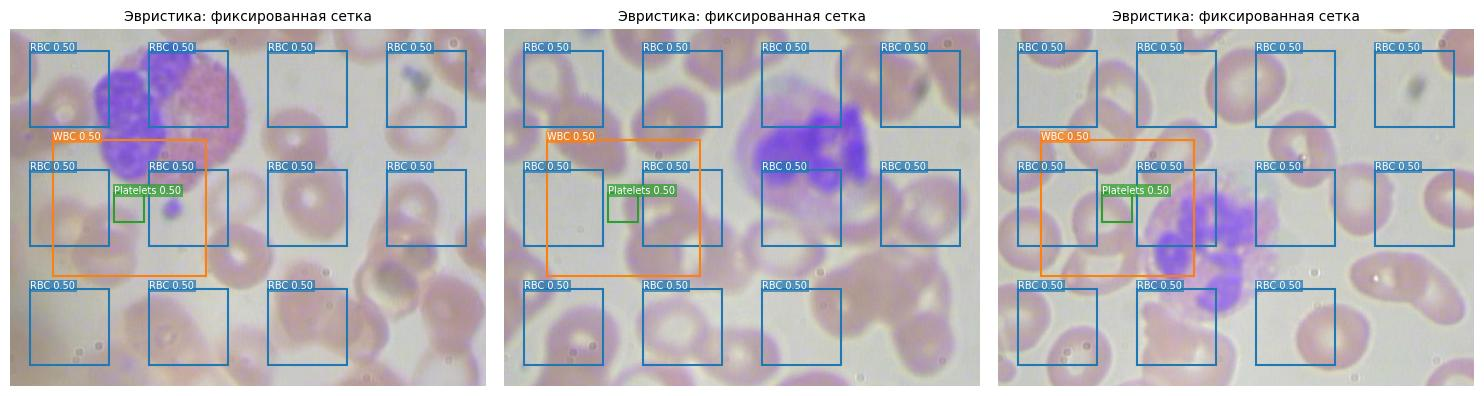

In [ ]:
# ваш код
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,r,p in zip(axs,records[FINAL_SPLIT][:3],heuristic_preds[:3]):
    draw_boxes(ax,Image.open(r['image']),p['boxes'],p['labels'],CLASSES,p['scores'],title='Эвристика: фиксированная сетка')
plt.tight_layout(); plt.show()


**Ответ:** У модели COCO получился mAP50 = 0, потому что среди её классов нет эритроцитов, лейкоцитов и тромбоцитов. Сеточная эвристика дала mAP50 = 0,0048. Небольшие попадания были у RBC (AP50 = 0,0145): на кадре много эритроцитов, поэтому бокс иногда совпадает случайно. У WBC и тромбоцитов AP50 оказался нулевым. Сетка не учитывает, где на снимке действительно лежат клетки, а у маленького бокса даже небольшой сдвиг сильно снижает IoU.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [ ]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [ ]:
# ваш код
TRAIN_ARGS=dict(epochs=EPOCHS,imgsz=IMGSZ,batch=BATCH,optimizer='AdamW',lr0=0.001,lrf=0.01,
    weight_decay=0.0005,cos_lr=True,warmup_epochs=0 if FAST_MODE else 3,patience=EPOCHS,
    seed=SEED,deterministic=True,amp=False,val=True,plots=True,save=True,
    hsv_h=0.015,hsv_s=0.3,hsv_v=0.3,degrees=15,translate=0.1,scale=0.3,
    fliplr=0.5,flipud=0.5,mosaic=0.5,close_mosaic=0 if FAST_MODE else 10,mixup=0.0)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')


New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=15, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.3, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, 

Нефинитные loss по эпохам (не заменяются): {'val/box_loss': [1], 'val/cls_loss': [1], 'val/dfl_loss': [1]}


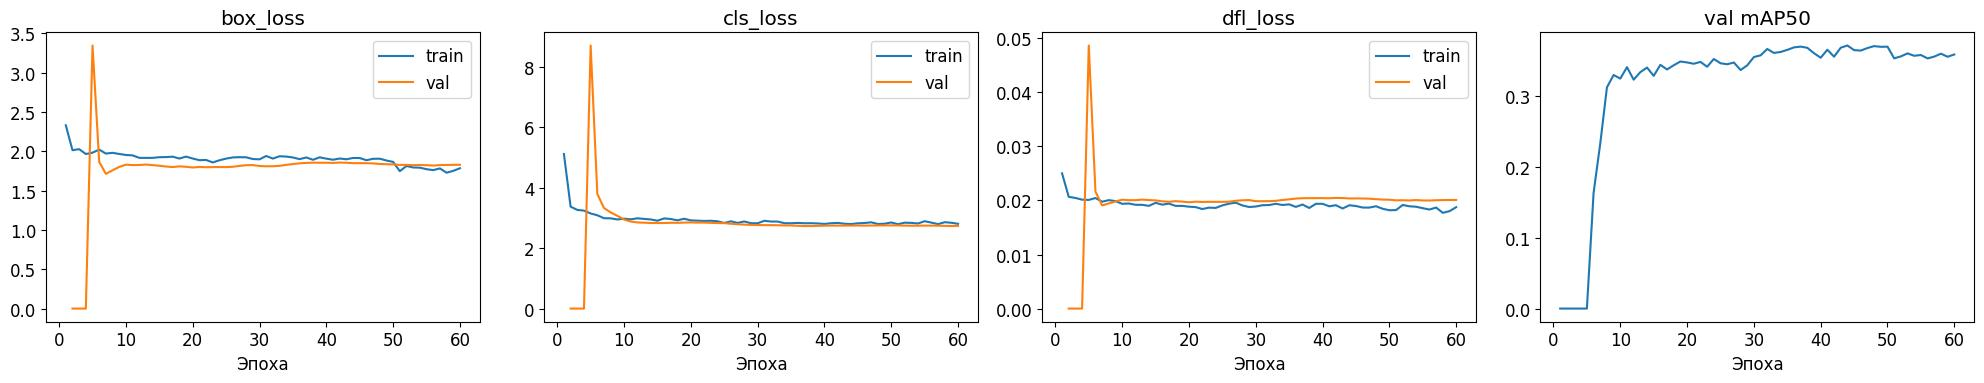

In [ ]:
# ваш код
history=read_results(run_dir)
assert len(history['epoch'])==EPOCHS, 'Mixed run history'
NONFINITE_MAIN={k:history['epoch'][~np.isfinite(v)].astype(int).tolist() for k,v in history.items() if 'loss' in k and not np.isfinite(v).all()}
print('Нефинитные loss по эпохам (не заменяются):',NONFINITE_MAIN)
loss_names=sorted({k.split('/',1)[1] for k in history if k.startswith(('train/','val/')) and 'loss' in k})
fig,axs=plt.subplots(1,len(loss_names)+1,figsize=(5*(len(loss_names)+1),4))
for ax,loss in zip(axs,loss_names):
    for split in ['train','val']:
        key=f'{split}/{loss}'
        if key in history: ax.plot(history['epoch'],history[key],label=split)
    ax.set(title=loss,xlabel='Эпоха'); ax.legend()
map_key=next(k for k in history if 'mAP50(' in k)
axs[-1].plot(history['epoch'],history[map_key]); axs[-1].set(title='val mAP50',xlabel='Эпоха')
plt.tight_layout(); plt.show()


**Ответ:** Я выбрал 640×640, чтобы не терять детали мелких тромбоцитов, и batch 16, который помещался в память T4. Запустил 60 эпох с AdamW, начальным lr 0,001 и плавным снижением шага. Повороты и отражения подходят для этих снимков, потому что у клеток нет фиксированной ориентации. Обучение заняло 7,7 минуты.

После первых эпох train loss снижался, а val loss в целом оставался стабильным. Явного переобучения по графику я не увидел. Лучший val mAP50 был 0,3708 на 44-й эпохе. Последние десять эпох этот результат не улучшили, поэтому 60 хватило для сравнения в этом опыте. На первой эпохе три значения validation loss были `NaN`. Я оставил их в `results.csv`. Итоговые метрики рассчитаны по лучшим весам отдельно.


## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [ ]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 917.5±268.8 MB/s, size: 19.8 KB)
val: Scanning /content/hw2_cv_final_1793897023517306373/data/yolo/labels/val.cache... 55 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 19.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.1it/s 1.9s
                   all         55        715      0.622      0.383      0.347       0.12
Speed: 4.2ms preprocess, 10.3ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /content/hw2_cv_final_1793897023517306373/runs_hw2_final/best_val
val


,map50,map50_95,precision,recall
RBC,0.073483,0.028864,1.000000,0.000000
WBC,0.643424,0.217536,0.475489,0.736842
Platelets,0.322691,0.112524,0.389185,0.413039


Ultralytics 8.4.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 576.5±131.1 MB/s, size: 20.1 KB)
val: Scanning /content/hw2_cv_final_1793897023517306373/data/yolo/labels/test... 55 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 1.6Kit/s 0.0s
val: New cache created: /content/hw2_cv_final_1793897023517306373/data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.6s
                   all         55        741      0.614      0.429      0.359      0.131
Speed: 10.4ms preprocess, 7.6ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /content/hw2_cv_final_1793897023517306373/runs_hw2_final/best_test
test


,map50,map50_95,precision,recall
RBC,0.078604,0.031261,1.000000,0.000000
WBC,0.575332,0.192989,0.398856,0.842105
Platelets,0.421765,0.168102,0.442957,0.445385


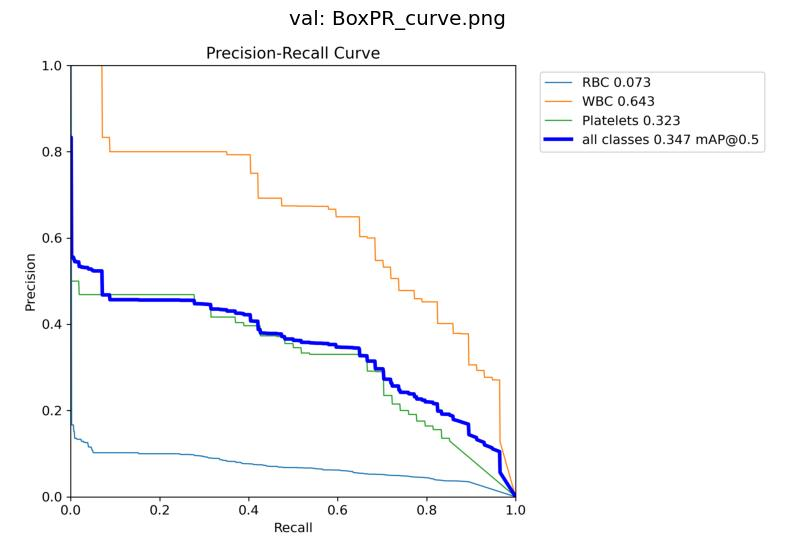

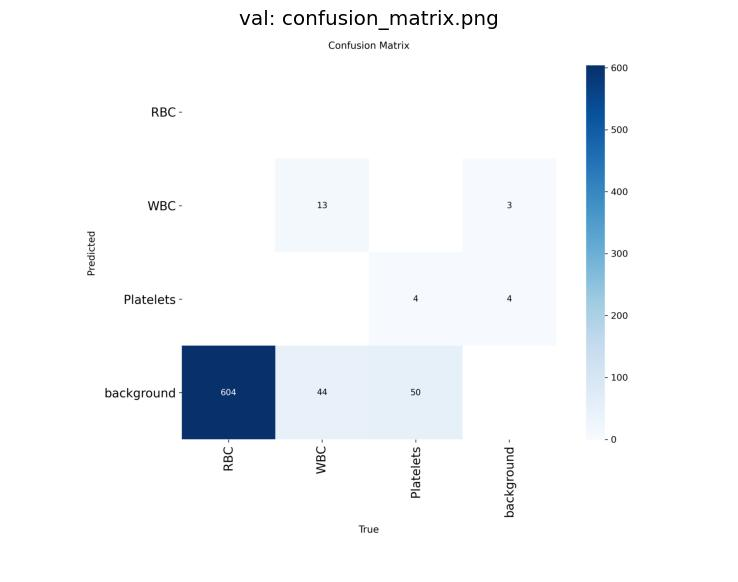

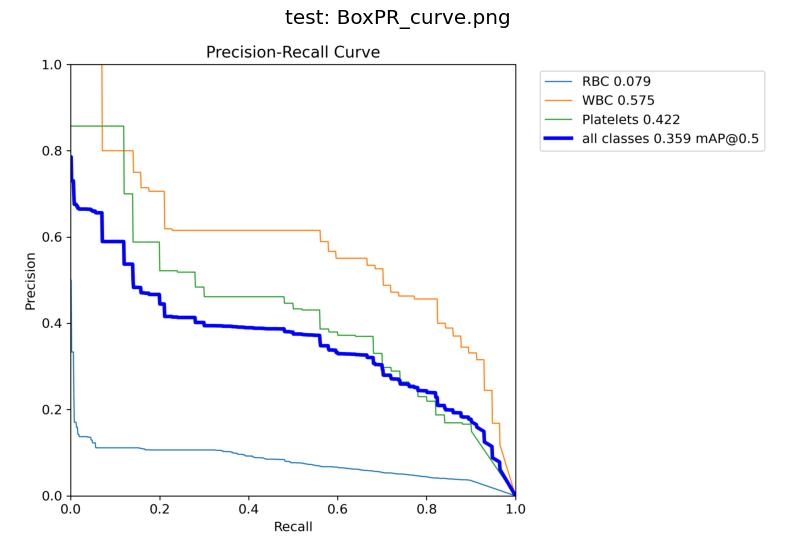

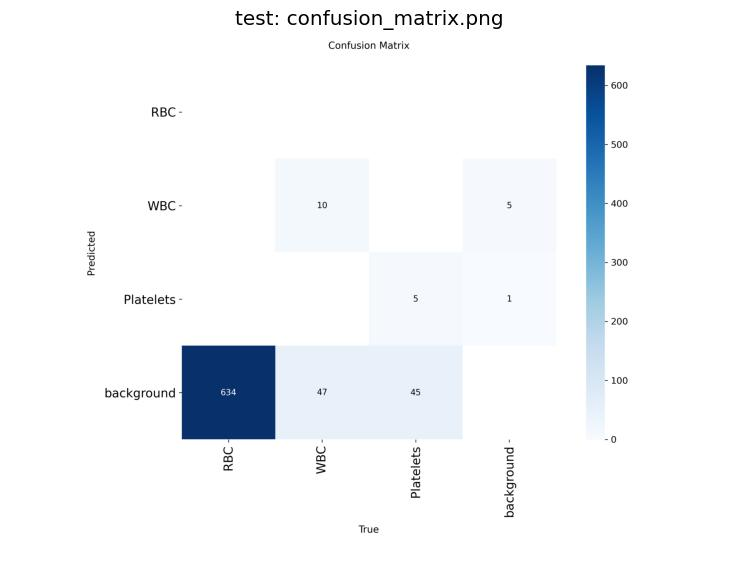

In [ ]:
# ваш код
def pack_metrics(m):
    per={}
    for j,c in enumerate(m.box.ap_class_index):
        per[CLASSES[int(c)]]=dict(map50=float(m.box.ap50[j]),map50_95=float(m.box.ap[j]),
                                precision=float(m.box.p[j]),recall=float(m.box.r[j]))
    return dict(map50=float(m.box.map50),map50_95=float(m.box.map),
                precision=float(m.box.mp),recall=float(m.box.mr),per_class=per)
VALIDATIONS={}; metric_objects={}
for split in ['val']+(['test'] if 'test' in records else []):
    m=val_metrics(best,split,f'best_{split}',plots=True,conf=0.001)
    metric_objects[split]=m; VALIDATIONS[split]=pack_metrics(m)
    print(split); display(pd.DataFrame(VALIDATIONS[split]['per_class']).T)
FINAL=dict(VALIDATIONS[FINAL_SPLIT],split=FINAL_SPLIT)
final_preds=predict_records(best,records[FINAL_SPLIT],conf=0.001)
manual_map50,manual_aps=evaluate_map50(final_preds,records[FINAL_SPLIT],len(CLASSES))
FINAL['manual_map50']=manual_map50
for split in metric_objects:
    paths=[]
    for pattern in ['*PR_curve.png','confusion_matrix.png']:
        paths.extend(sorted(Path(metric_objects[split].save_dir).glob(pattern)))
    for p in paths:
        fig,ax=plt.subplots(figsize=(10,7)); ax.imshow(plt.imread(p)); ax.axis('off'); ax.set_title(f'{split}: {p.name}'); plt.show()
worst=min(FINAL['per_class'],key=lambda c:FINAL['per_class'][c]['map50_95'])


In [ ]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.3586,
 'map50_95': 0.1308,
 'precision': 0.6139,
 'recall': 0.4292,
 'split': 'test',
 'manual_map50': 0.3388}

**Ответ:** На val mAP50 составил 0,3465, а mAP50–95 — 0,1196. На тесте эти значения составили 0,3586 и 0,1308. Хуже всего получились RBC с AP50–95 = 0,0313, хотя это самый частый класс, а его боксы крупнее боксов тромбоцитов. На примерах эритроциты плотно лежат и часто перекрываются, местами разметка неполная. Для замороженного backbone результат по RBC на val намного выше, поэтому я бы отдельно проверил, как полное дообучение меняет предобученные признаки.

В матрице строка background показывает пропущенные объекты, а столбец background — боксы без совпавшего объекта. На val все 604 RBC попали в строку background при порогах этой матрицы. mAP50–95 ниже, потому что для высоких IoU бокс должен точнее совпасть с разметкой. Мой расчёт дал mAP50 = 0,3388, примерно на 0,020 ниже Ultralytics. В шаблоне AP считается по всем точкам PR-кривой, а Ultralytics использует интерполяцию по 101 точке. Также могут отличаться детали сопоставления боксов.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [ ]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')

def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    # ваш код
    a=np.asarray(a,dtype=float).reshape(-1,4); b=np.asarray(b,dtype=float).reshape(-1,4)
    wh=np.maximum(0,np.minimum(a[:,None,2:],b[None,:,2:])-np.maximum(a[:,None,:2],b[None,:,:2]))
    inter=wh.prod(axis=2)
    area_a=np.maximum(0,a[:,2:]-a[:,:2]).prod(axis=1)
    area_b=np.maximum(0,b[:,2:]-b[:,:2]).prod(axis=1)
    union=area_a[:,None]+area_b[None,:]-inter
    return np.divide(inter,union,out=np.zeros_like(inter),where=union>0)

def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    # ваш код
    pb=np.asarray(pred['boxes']).reshape(-1,4); gb=np.asarray(gt['boxes']).reshape(-1,4)
    pl=np.asarray(pred['labels']); gl=np.asarray(gt['labels'])
    ious=box_iou_np(pb,gb); found=np.zeros(len(gb),bool); associated=np.zeros(len(gb),bool)
    cats=['background']*len(pb)
    for i in np.argsort(-np.asarray(pred['scores']),kind='stable'):
        same=gl==pl[i]
        candidates=np.flatnonzero(same & ~found & (ious[i]>=iou_hit))
        if len(candidates):
            j=candidates[np.argmax(ious[i,candidates])]; cats[i]='tp'; found[j]=True; associated[j]=True; continue
        candidates=np.flatnonzero(~same & (ious[i]>=iou_hit))
        if len(candidates):
            j=candidates[np.argmax(ious[i,candidates])]; cats[i]='class'; associated[j]=True; continue
        candidates=np.flatnonzero(same & ~found & (ious[i]>=iou_loc) & (ious[i]<iou_hit))
        if len(candidates):
            j=candidates[np.argmax(ious[i,candidates])]; cats[i]='localization'; associated[j]=True
    return cats,np.flatnonzero(~associated).tolist()


In [ ]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


,count,share_of_events
tp,14,0.019499
class,0,0.000000
localization,7,0.009749
background,3,0.004178
missed,694,0.966574


,tp,class,localization,background,missed
RBC,0,0,0,0,604
WBC,11,0,5,0,41
Platelets,3,0,2,3,49


Доли считаются среди событий (предсказания + missed); это не стандартные FP/FN rates.


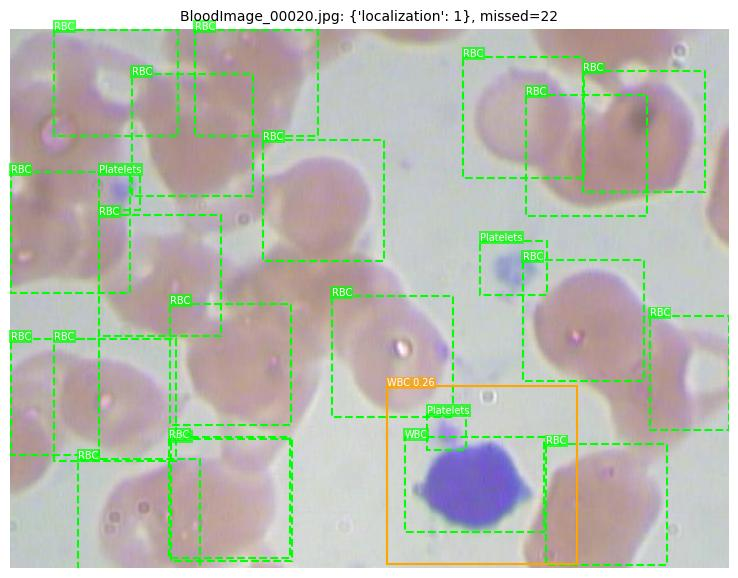

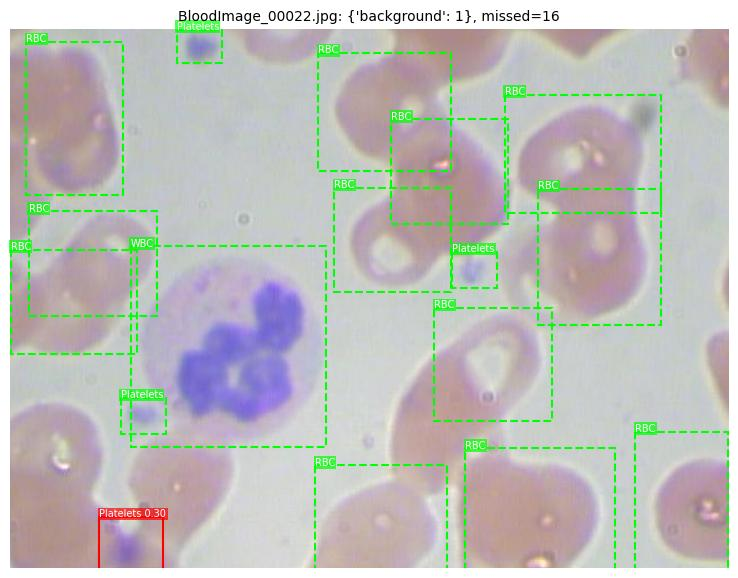

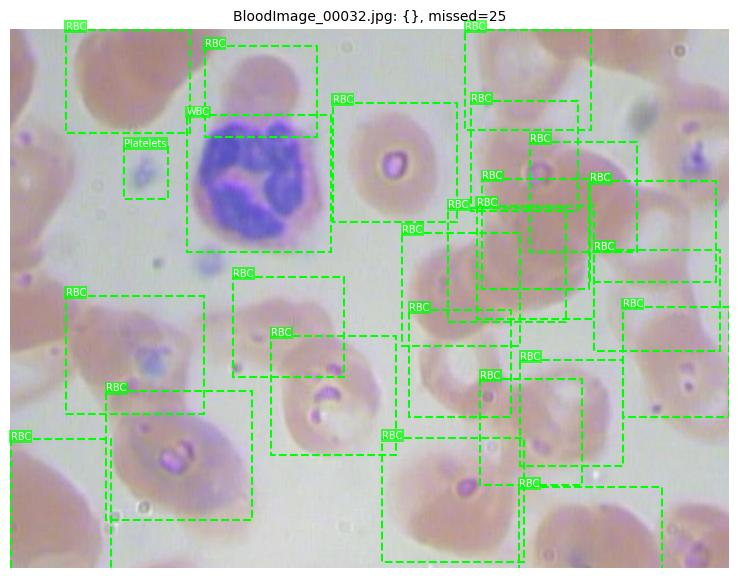

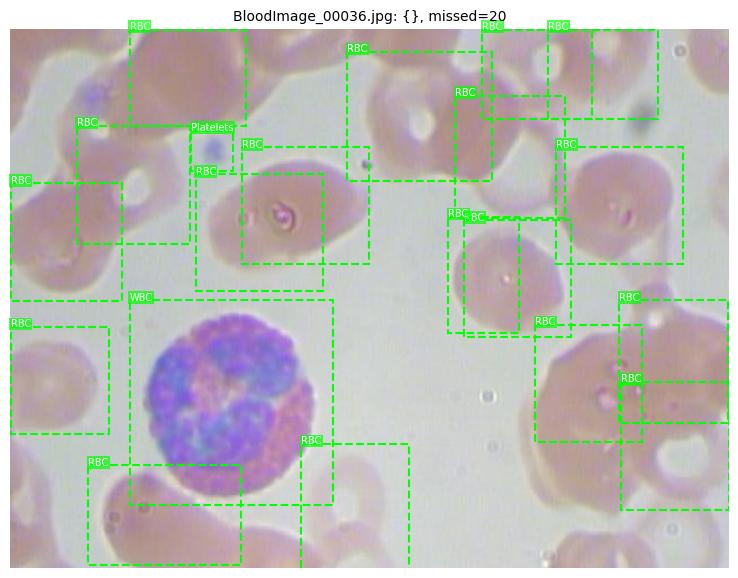

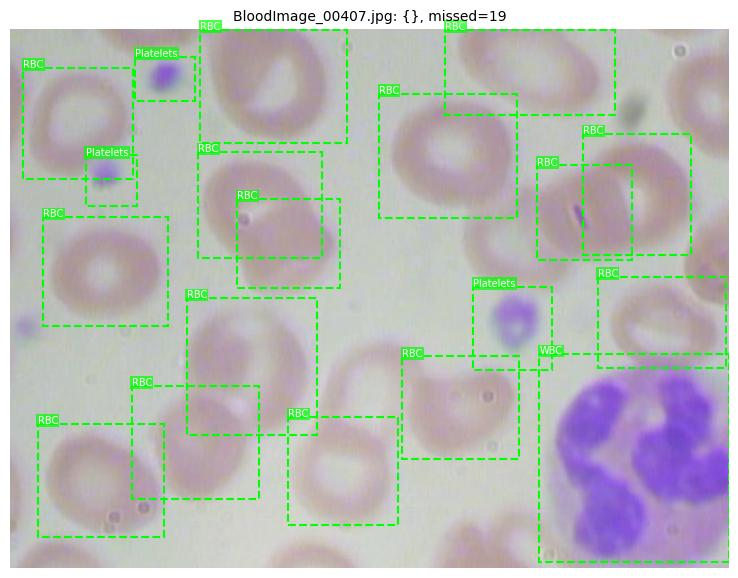

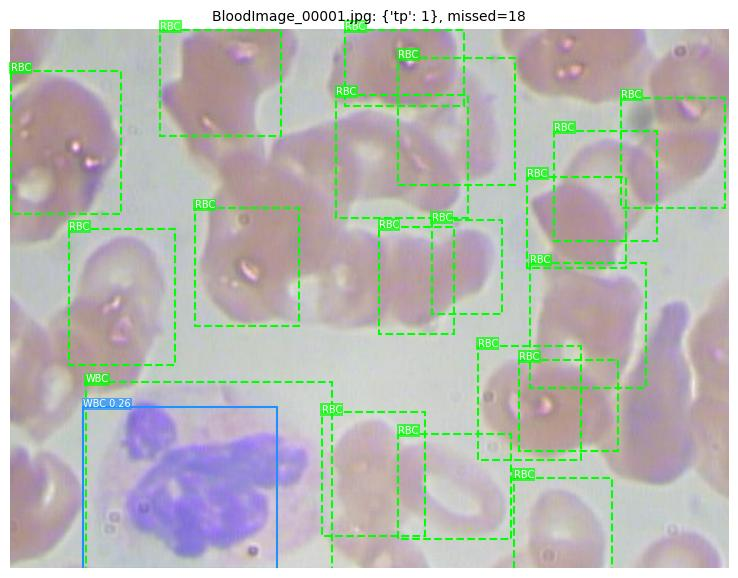

GT: green dashed; TP: blue; class: magenta; localization: orange; background: red.


In [ ]:
# ваш код
val_preds=predict_records(best,records['val'],conf=CONF_ERRORS)
ERRORS={k:0 for k in ERROR_TYPES}; error_by_class={c:Counter({k:0 for k in ERROR_TYPES}) for c in CLASSES}
error_examples=[]
for idx,(p,r) in enumerate(zip(val_preds,records['val'])):
    cats,missed=categorize_predictions(p,r)
    for cat,c in zip(cats,p['labels']): ERRORS[cat]+=1; error_by_class[CLASSES[int(c)]][cat]+=1
    ERRORS['missed']+=len(missed)
    for j in missed: error_by_class[CLASSES[int(r['labels'][j])]]['missed']+=1
    present=(set(cats)-{'tp'})|({'missed'} if missed else set())
    if present: error_examples.append((idx,present,cats,missed))
error_table=pd.DataFrame({'count':ERRORS}); error_table['share_of_events']=error_table['count']/max(1,sum(ERRORS.values()))
display(error_table); display(pd.DataFrame(error_by_class).T)
print('Доли считаются среди событий (предсказания + missed); это не стандартные FP/FN rates.')
chosen=[]
for cat in ERROR_TYPES[1:]:
    candidate=next((e for e in error_examples if cat in e[1] and e[0] not in [x[0] for x in chosen]),None)
    if candidate: chosen.append(candidate)
for e in sorted(error_examples,key=lambda e:sum(c!='tp' for c in e[2])+len(e[3]),reverse=True):
    if len(chosen)>=6: break
    if e[0] not in [x[0] for x in chosen]: chosen.append(e)
for idx,present,cats,missed in chosen:
    r=records['val'][idx]; p=val_preds[idx]
    fig,ax=plt.subplots(figsize=(10,7))
    draw_boxes(ax,Image.open(r['image']),r['boxes'],r['labels'],CLASSES,color='lime',linestyle='--')
    for k,cat in enumerate(cats):
        draw_boxes(ax,None,p['boxes'][k:k+1],p['labels'][k:k+1],CLASSES,p['scores'][k:k+1],
                   color={'tp':'dodgerblue','class':'magenta','localization':'orange','background':'red'}[cat])
    ax.set_title(f"{Path(r['image']).name}: {dict(Counter(cats))}, missed={len(missed)}",fontsize=10)
    Path("analysis_plots").mkdir(exist_ok=True)
    fig.savefig(Path("analysis_plots")/f"error_{idx}.png",dpi=130,bbox_inches="tight")
    plt.show()
print('GT: green dashed; TP: blue; class: magenta; localization: orange; background: red.')


**Ответ:** При `conf=0.25` таблица показывает 694 пропуска (96,7% всех событий, включая верные предсказания). Из них 604 — эритроциты. На `BloodImage_00032.jpg`, `00036` и `00407` нет ни одного предсказания выше порога. Всего на этих кадрах пропущено 64 размеченные клетки. На `00001` модель нашла только лейкоцит и пропустила 18 объектов, а на `00020` рамка вокруг лейкоцита получилась слишком большой. На `00022` предсказанный тромбоцит остался без пары в разметке. По снимку трудно сказать, лишний ли это бокс или разметка неполная.

Я бы сначала посмотрел PR-кривую и попробовал более низкий порог на val, чтобы понять, сколько пропусков вызвано низкой уверенностью модели. Затем проверил бы ещё один запуск с замороженным backbone, поскольку этот вариант лучше находил RBC на val.


## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [ ]:
# ваш код
ABLATION_ARGS=dict(TRAIN_ARGS,freeze=len(arch.yaml['backbone']))
abl_model,RUN_TIMES['ablation'],abl_dir=train_yolo('freeze_backbone',**ABLATION_ARGS)
abl_best=YOLO(abl_dir/'weights'/'best.pt')
abl_history=read_results(abl_dir)
assert len(abl_history['epoch'])==EPOCHS, 'Mixed ablation history'
NONFINITE_ABLATION={k:abl_history['epoch'][~np.isfinite(v)].astype(int).tolist() for k,v in abl_history.items() if 'loss' in k and not np.isfinite(v).all()}
print('Нефинитные loss абляции по эпохам (не заменяются):',NONFINITE_ABLATION)
abl_metrics=pack_metrics(val_metrics(abl_best,'val','ablation_val',plots=False,conf=0.001))
ABLATION=dict(changed='freeze',values=[0,len(arch.yaml['backbone'])],split='val',
    baseline=dict(VALIDATIONS['val'],train_time_sec=RUN_TIMES['train']),
    frozen=dict(abl_metrics,train_time_sec=RUN_TIMES['ablation']),
    same_seed=SEED,same_initial_weights=WEIGHTS)
display(pd.DataFrame([dict(variant='full',**{k:VALIDATIONS['val'][k] for k in ['map50','map50_95']},seconds=RUN_TIMES['train']),
                     dict(variant='freeze backbone',**{k:abl_metrics[k] for k in ['map50','map50_95']},seconds=RUN_TIMES['ablation'])]))


New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=15, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=11, half=False, hsv_h=0.015, hsv_s=0.3, hsv_v=0.3, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=freeze_backbone, nbs=64, nms=False, opset=N

,variant,map50,map50_95,seconds
0,full,0.346532,0.119641,459.742309
1,freeze backbone,0.606072,0.276500,341.389854


**Ответ:** Я заморозил первые 11 слоёв backbone. На тех же 55 кадрах val mAP50 вырос с 0,3465 до 0,6061, а mAP50–95 — с 0,1196 до 0,2765. Обучение заняло 5,7 минуты вместо 7,7. На этой выборке заморозка сэкономила время и дала более высокую оценку. Я бы повторил оба запуска с другими seed, чтобы проверить, сохраняется ли эффект.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** На 55 тестовых снимках YOLO26n после дообучения дала mAP50 = 0,3586, а сеточная эвристика — 0,0048. При усреднении по более строгим порогам IoU mAP50–95 модели составил 0,1308. На val при `conf=0.25` модель пропустила 694 объекта, из них 604 — эритроциты. На той же val-выборке заморозка 11 слоёв backbone подняла mAP50–95 с 0,1196 до 0,2765. Время обучения сократилось с 7,7 до 5,7 минуты. Результат абляции получен на 55 снимках с одним seed, а часть видимых клеток пропущена в разметке. Дальше я бы повторил сравнение с несколькими seed и на val проверил, насколько можно уменьшить число пропусков настройкой порога уверенности.


### Сохранение результатов обязательной части



In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


In [ ]:
# ваш код
(artifact_dir/'model_info.json').write_text(json.dumps(json_ready(MODEL_INFO),ensure_ascii=False,indent=2))
(artifact_dir/'dataset_manifest.json').write_text(json.dumps(dict(commit=DATA_COMMIT,
    cleaning=dict(cleaning),splits={s:[Path(r['image']).name for r in rs] for s,rs in records.items()}),indent=2))
stats.to_csv(artifact_dir/'dataset_stats.csv',index=False)
pd.DataFrame(error_by_class).T.to_csv(artifact_dir/'errors_by_class.csv')
shutil.copy(abl_dir/'results.csv',artifact_dir/'ablation_results.csv')
shutil.copy(source_root/'LICENSE',artifact_dir/'BCCD_LICENSE.txt')
(artifact_dir/'environment.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','list','--format=freeze'],text=True))
for split,m in metric_objects.items():
    for path in Path(m.save_dir).glob('*.png'): shutil.copy(path,artifact_dir/f'{split}_{path.name}')

for p in Path("analysis_plots").glob("error_*.png"): shutil.copy(p,artifact_dir/p.name)

(artifact_dir/'numerical_diagnostics.json').write_text(json.dumps(dict(main=NONFINITE_MAIN,ablation=NONFINITE_ABLATION),indent=2))


147

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [ ]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [ ]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [ ]:
if '6.3' in BONUS_TASKS:
    # ваш код
    import yaml
    domain_results={}
    for kind in ['dark','noise','jpeg']:
        root=DATA_ROOT/f'shift_{kind}'
        image_dir=root/'images'/'val'; label_dir=root/'labels'/'val'
        image_dir.mkdir(parents=True,exist_ok=True); label_dir.mkdir(parents=True,exist_ok=True)
        rng=np.random.default_rng(SEED)
        for r in records['val']:
            with Image.open(r['image']) as im: arr=np.array(im.convert('RGB'))
            if kind=='dark': arr=np.round(arr.astype(float)*0.35).astype(np.uint8)
            elif kind=='noise': arr=np.clip(arr.astype(float)+rng.normal(0,25,arr.shape),0,255).astype(np.uint8)
            filename=Path(r['image']).stem+('.jpg' if kind=='jpeg' else '.png')
            Image.fromarray(arr).save(image_dir/filename,**({'quality':10} if kind=='jpeg' else {}))
            (label_dir/(Path(filename).stem+'.txt')).write_text(to_yolo(r['boxes'],r['labels'],r['width'],r['height']))
        cfg=root/'data.yaml'; cfg.write_text(yaml.safe_dump(dict(path=str(root.resolve()),train='images/val',val='images/val',names=CLASSES)))
        m=best.val(data=str(cfg),split='val',imgsz=IMGSZ,batch=BATCH,device=DEVICE,workers=WORKERS,
                   project=str(RUNS.resolve()),name=f'domain_{kind}',exist_ok=True,verbose=False,plots=False,conf=0.001)
        domain_results[kind]=pack_metrics(m)
    display(pd.DataFrame({'clean':VALIDATIONS['val'],**domain_results}).T[['map50','map50_95','precision','recall']])
    (artifact_dir/'domain_shift.json').write_text(json.dumps(json_ready(domain_results),indent=2))


Ultralytics 8.4.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2833.7±790.4 MB/s, size: 181.2 KB)
val: Scanning /content/hw2_cv_final_1793897023517306373/data/shift_dark/labels/val... 55 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 55/55 1.6Kit/s 0.0s
val: New cache created: /content/hw2_cv_final_1793897023517306373/data/shift_dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.6it/s 0.9s
                   all         55        715   0.000944     0.0193   0.000716   0.000114
Speed: 1.2ms preprocess, 4.8ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.0 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (pin

,map50,map50_95,precision,recall
clean,0.346532,0.119641,0.621558,0.383294
dark,0.000716,0.000114,0.000944,0.019316
noise,0.35724,0.123099,0.641467,0.4126
jpeg,0.340525,0.11845,0.627886,0.393411


**Ответ:** Больше всего помешало затемнение до 35% исходной яркости. mAP50 упал с 0,3465 до 0,0007, а mAP50–95 — с 0,1196 до 0,0001. У лейкоцитов и тромбоцитов AP после затемнения упал до нуля. После шума mAP50–95 получился 0,1231, после JPEG-сжатия — 0,1185. Я бы добавил на обучении случайное затемнение и изменение гаммы, а затем повторил проверку на тех же снимках.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [ ]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**


## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [ ]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

In [ ]:
# ваш код
(artifact_dir/'run_status.json').write_text(json.dumps(dict(completed=True,fast_mode=FAST_MODE,
    bonus_tasks=sorted(BONUS_TASKS),device=DEVICE_NAME),indent=2))
archive_path=shutil.make_archive('hw2_cv_artifacts_fast' if FAST_MODE else 'hw2_cv_artifacts','zip',root_dir='.',base_dir='artifacts')
print('Готово:',archive_path)
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    pass


Готово: /content/hw2_cv_final_1793897023517306373/hw2_cv_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>